In [1]:
#General tools
import numpy as np
import pandas as pd
import seaborn as sns
import os
import pymol2

#Coded tools, you need to connect it manually sometimes
from generate_graph_new import protein_pocket, make_protein_ligand_complex

#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap


In [2]:
#Pocket docking

# Define your directories
dock_pdbqt_dir = '/data/projects/Chemdocking/dock_score/destabilizer/'
protein_pdb_dir = "/data/projects/Chemdocking/VirtualDockingLab/data/screen_8000/protein/target.pdb"
complex_pdb_dir = "tmp/complex.pdb"
complex_csv_dir = "complex.csv"
pocket_dir = '/projectbig/jupyternotebook/jrivera/output/pocket_results'


In [3]:
#Docked ligand data filtering and selection

# Open a loop to access all of the file in the directories
for files in os.listdir(dock_pdbqt_dir):
    
    # Filter only pdb files
    if files.split('.') [1] != 'pdb':
        continue
        
    #Make temporary folder
    if not os.path.exists("tmp"):
        os.mkdir("tmp")

    # Make ligand pose path
    docking_dir = os.path.join(dock_pdbqt_dir, files)

    # Conver ligand posed pdb file to several sdf files
    ! /home/jrivera/envs/chem/bin/obabel {docking_dir} -O tmp/ligand_pose_.sdf -m

    # Make protein-ligand complex file (take the first ligand pose)
    make_protein_ligand_complex(protein_pdb_dir, "tmp/ligand_pose_1.sdf", complex_pdb_dir)

    #From all of the poses, take the ones with distance lower than 6 Armstrong
    pocket = protein_pocket(complex_pdb_dir, ligand_id = 'UNK', threshold = 6)

    #Giver your file the correct name
    csv_file_name = files.split('.')[0] + '.csv'
    docking_dir = os.path.join(pocket_dir, csv_file_name)
    pocket.to_csv(docking_dir)

    #remove temporary folder
    os.system("rm -r tmp") 

1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule co

In [4]:
#Ligand preparation for heatmap

# Go through all of the file that are in the directory
pocket_data = os.listdir(pocket_dir)        


PAH_ligands= {}

# Open and filter through CSV
for filename in pocket_data:             
    if filename.split('.') [1] != 'csv':
        continue                         

    #Open only the filtered files
    pocket_dir = os.path.join(pocket, filename)  

    #Read your filtered files    
    ligands = pd.read_csv(pocket_dir)

    #Create a binary data set to represent the data in a heat map
    ligands_processed = [1 if i in list(ligands['index']) else 0 for i in range(453)]

    #Add the data for your dictionary       
    PAH_ligands[filename.split('_')[4]] = ligands_processed
    
    
    #print (PAH_ligands)


In [5]:
#Dictionary sorting
PAH_ligands_sorted = dict(sorted(PAH_ligands.items(), key=lambda item: int(item[0])))

#PAH_ligands.items() it will call the dictionary items ( ,  )
#Transform your data into int to sorted, key=lambda sorted by number, not alphabetically

#print (PAH_ligands_sorted)

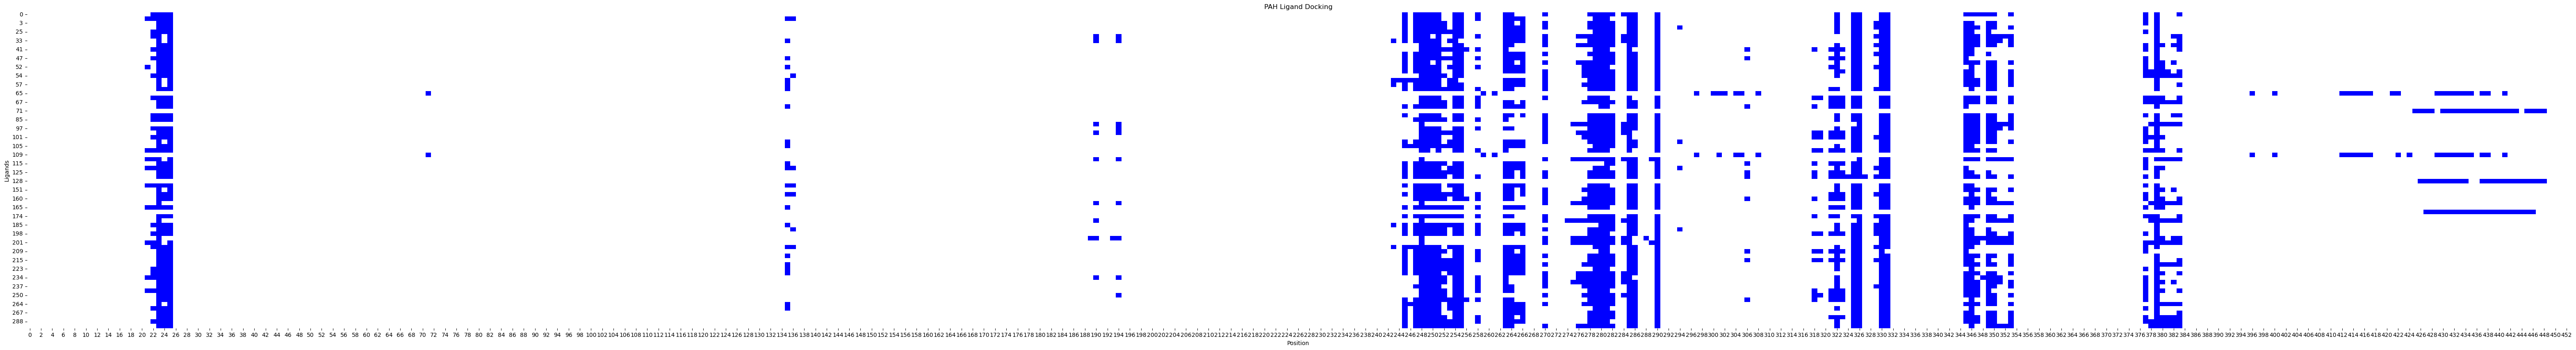

In [6]:
#Make the heatmap

#Make your data a dataframe in pd
heatmap_PAH_ligands = pd.DataFrame(PAH_ligands_sorted).T

plt.figure(figsize=(80, 10))
sns.heatmap(heatmap_PAH_ligands, cmap=["white", "blue"], cbar=False, linewidths=0.001, linecolor='gray')

xticks = list(range(0, 453, 2))


plt.title('PAH Ligand Docking')
plt.xlabel('Position')
plt.ylabel('Ligands')

#plt.savefig('/projectbig/jupyternotebook/jrivera/output/figures/Docking/Ligand_destabilizer.pdf')
plt.show()